In [1]:
from typing import TypedDict , List
from langgraph.graph import StateGraph
import math

In [2]:
class AgentState(TypedDict):
    name : str
    values : List[int]
    operation : str
    result : str

In [3]:
def process_data(state : AgentState) ->AgentState :
    """ process the input values """
    operator = state['operation']

    if operator == "+":
        state['result'] = f"Hey {state['name']} - your answer is {sum(state['values'])}"   # type: ignore
    elif operator == '*':
        state['result'] = f"Hey {state['name']} - your answer is {math.prod(state['values'])}"
    else : 
        state['result'] = "invalid"

    return state

In [4]:
graph = StateGraph(AgentState)

graph.set_finish_point("process_data")
graph.add_node('process_data', process_data)
graph.set_entry_point('process_data')

app = graph.compile()

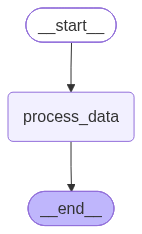

In [5]:
from IPython.display import display, Image
display(Image(app.get_graph().draw_mermaid_png()))

In [12]:
res = app.invoke({
    'name':"dev",
    'values':[1,2,3,4,5],
    "operation" :"+"
})  # type: ignore

res['result']

'Hey dev - your answer is 15'